# Simple Multimodal Test

Compare 3 models to assess performance:

1. Trained only one one modality
2. Trained jointly on all modalities as vector output
3. One main model with separate models for other modalities as additional input

In [13]:
import numpy as np
import torch
import itertools
import matplotlib.pyplot as plt
from pyro.infer import NUTS, MCMC, Predictive
from pyro.infer.autoguide import init_to_sample
import pyro.distributions as dist

import mmbo.examples.testfunc as testfunc
from mmbo.nn import TIBNN


In [14]:
# Consistent network parameters
width = 400
depth = 2
output_bias = True
bias_ordering = True
bias_positive = True
residual_prior = dist.Exponential(10)

# Consistent sampling parameters
warmup_steps = 100
num_samples = 50
num_chains = 2

In [31]:
def plot_predictions(model, mcmc, x_plot, y_plot, x_train, y_train, pred_site="mu"):
    # Set up figure/axes
    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [1.05*x_plot.min() - 0.05*x_plot.max(), 1.05*x_plot.max() - 0.05*x_plot.min()]
    ylims = [1.5*y_plot.min() - 0.5*y_plot.max(), 1.5*y_plot.max() - 0.5*y_plot.min()]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)
    # Plot predicted means
    preds = Predictive(model, mcmc.get_samples(), return_sites=[pred_site])(x_plot)
    for inst in range(preds[pred_site].shape[0]):
        y_inst = preds[pred_site][inst,:,-1]
        ax.plot(x_plot.squeeze(), y_inst, '-', linewidth=0.5, alpha=0.2, color="red", zorder = 0)
    # Plot confidence bands
    y_pred_mean = preds[pred_site].mean(0)[:,-1]
    y_pred_std = preds[pred_site].std(0)[:,-1]
    ax.plot(x_plot.squeeze(), y_pred_mean, '-', linewidth=3, color="#408765", label="predictive mean", zorder = 10)
    ax.fill_between(x_plot.squeeze(), y_pred_mean - 2 * y_pred_std, y_pred_mean + 2 * y_pred_std, alpha=0.6, color='#86cfac', zorder=5)
    # Plot true function
    ax.plot(x_plot.squeeze(), y_plot.squeeze(), 'b-', linewidth=3, label="true function", zorder = 15)
    # Plot data points
    ax.plot(x_train.squeeze(), y_train.squeeze(), 'ko', markersize=4, label="observations", zorder = 20)
    plt.legend(loc="lower right")

## Generate test data

In [16]:
def _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full, shuffle):
    rng = np.random.default_rng(seed)
    ntrain = ntrainpergroup * (2 ** len(modes) - 1)
    # Training Data
    X_train = np.linspace(xmin, xmax, num=ntrain)
    if shuffle:
        rng.shuffle(X_train)
    Y_train = np.empty((ntrain, len(modes)))
    Y_train.fill(np.nan)
    combinations = list(itertools.chain.from_iterable([itertools.combinations(range(len(modes)), r) for r in range(1,len(modes)+1)])) * ntrainpergroup
    for r in range(ntrain):
        for c in combinations[r]:
            Y_train[r,c] = func(X_train[r], modes[c])
    Y_train_full = np.zeros((ntrain, len(modes)))
    for i,m in enumerate(modes):
        Y_train_full[:,i] = func(X_train, m)
    # Package and return
    X_train_pt = torch.Tensor(np.float32(X_train.reshape((ntrain,1))))
    Y_train_pt = torch.Tensor(np.float32(Y_train))
    Y_train_full_pt = torch.Tensor(np.float32(Y_train_full))
    if full:
        return X_train_pt, Y_train_pt, Y_train_full_pt
    else:
        return X_train_pt, Y_train_pt

def _molecule_train_data(func, xmin, xmax, ntrainpergroup, seed, full, shuffle):
    modes = func.modes
    return _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full, shuffle)

def li2_train_data(ntrainpergroup, seed=None, full=False, shuffle=True):
    return _molecule_train_data(testfunc.li2_energy, 0.5, 11.0, ntrainpergroup, seed, full, shuffle)

def be2_train_data(ntrainpergroup, seed=None, full=False, shuffle=True):
    return _molecule_train_data(testfunc.be2_energy, 0.5, 5.0, ntrainpergroup, seed, full, shuffle)

def nice_periodic_train_data(ntrainpergroup, nummodes=5, seed=None, full=False, shuffle=True):
    return _train_data(testfunc.nice_periodic, list(range(nummodes)), -np.pi, np.pi, ntrainpergroup, seed, full, shuffle)

Text(0.5, 1.0, 'Training Data')

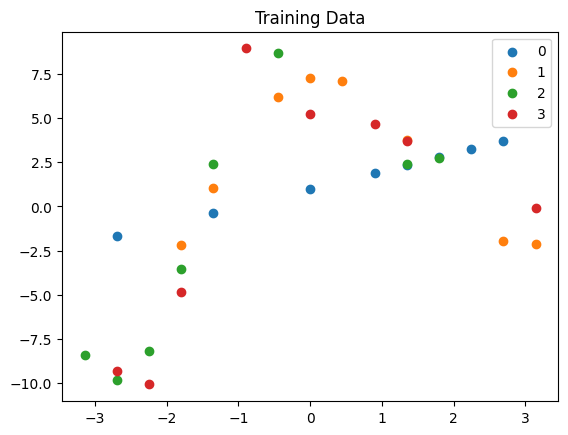

In [17]:
n_modes = 4

X_train, Y_train, Y_train_full = nice_periodic_train_data(1, n_modes, 1234, full=True)

X_plot, _, Y_plot = nice_periodic_train_data(100, n_modes, 1234, full=True, shuffle=False)

for i,m in enumerate(range(n_modes)):
    plt.scatter(X_train.detach(), Y_train.detach()[:,i], label=m)
plt.legend(loc="upper right")
plt.title("Training Data")

## 1. Single Modality Model

In [18]:
single = TIBNN.from_data(X_train, Y_train[:,-1:], width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_single = NUTS(single, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_single = MCMC(nuts_single, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
mcmc_single.run(X_train, Y_train[:,-1:])

Warmup [1]:   0%|          | 0/150 [00:00, ?it/s]

Warmup [2]:   0%|          | 0/150 [00:00, ?it/s]

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/pyro/distributions/torch_patch.py:74: TracerWarning: torch.as_tensor results are registered as constants in the trace. You can safely ignore this warning if you use this function to create tensors out of constant variables that would be the same every time you call this function. In any other case, this might cause the trace to be incorrect.
  value = torch.as_tensor(
/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/pyro/poutine/subsample_messenger.py:70: TracerWarning: torch.tensor results are registered as constants in the trace. You can safely ignore this warning if you use this function to create tensors out of constant variables that would be the same every time you call this function. In any other case, this might cause the trace to be incorrect.
  result = torch.tensor(0.0, device=self.device)
/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/pyro/distributions/util.py:231: TracerWarning: C

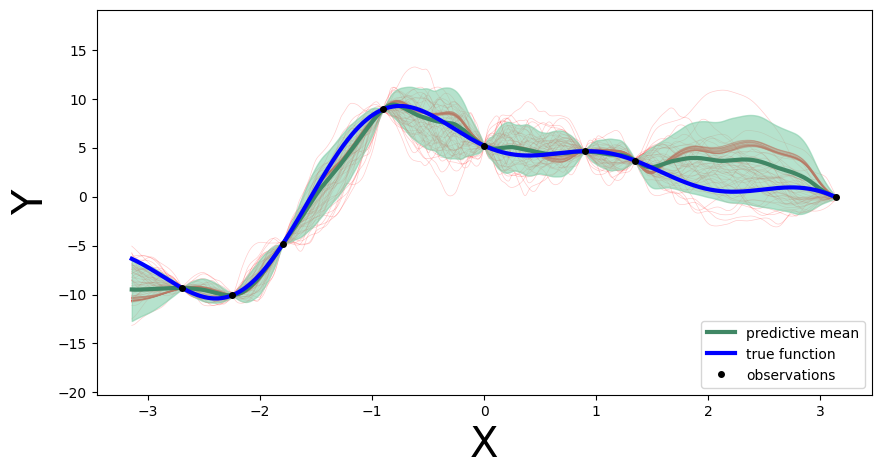

In [32]:
plot_predictions(single, mcmc_single, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:])

In [37]:
mcmc_single.get_samples()['sigma'].mean()

tensor(0.0679)

## 2. Joint output Model

In [22]:
multiple = TIBNN.from_data(X_train, Y_train, width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_multiple = NUTS(multiple, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_multiple = MCMC(nuts_multiple, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
mcmc_multiple.run(X_train, Y_train)

Warmup [1]:   0%|          | 0/150 [00:00, ?it/s]

Warmup [2]:   0%|          | 0/150 [00:00, ?it/s]

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/pyro/distributions/torch_patch.py:74: TracerWarning: torch.as_tensor results are registered as constants in the trace. You can safely ignore this warning if you use this function to create tensors out of constant variables that would be the same every time you call this function. In any other case, this might cause the trace to be incorrect.
  value = torch.as_tensor(
/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/pyro/poutine/subsample_messenger.py:70: TracerWarning: torch.tensor results are registered as constants in the trace. You can safely ignore this warning if you use this function to create tensors out of constant variables that would be the same every time you call this function. In any other case, this might cause the trace to be incorrect.
  result = torch.tensor(0.0, device=self.device)
/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/pyro/distributions/util.py:231: TracerWarning: C

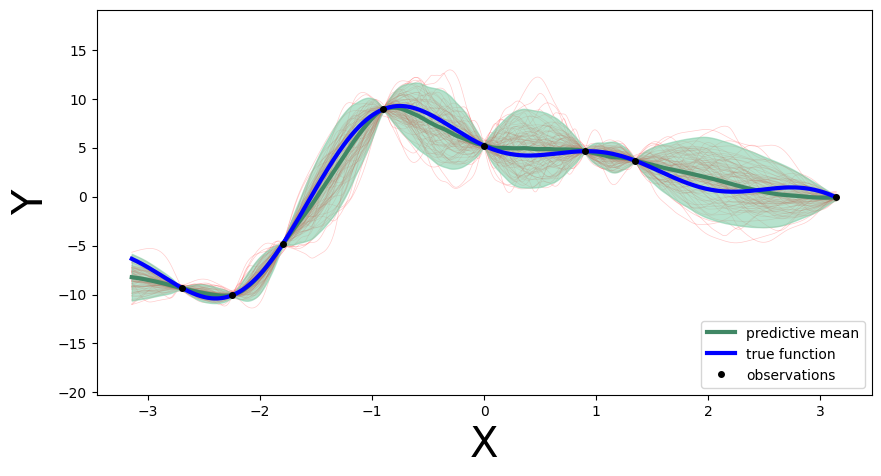

In [33]:
plot_predictions(multiple, mcmc_multiple, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:])

In [38]:
mcmc_multiple.get_samples()['sigma'].mean()

tensor(0.1087)